In [7]:
  # How this notebook is organised (the step numbers are used in the code comments below)
  #   Steps 1-8    load the data, set the target, drop unusable columns and duplicate rows,
  #                stratified 80/20 train/test split, lock the test set away
  #   Step 9       exploratory data analysis on the training set (Tables 1-3, Figures 1-4)
  #   Step 10      preprocessing recipe: missing-value indicators, median imputation, standardisation
  #   Steps 11-13  nested cross-validation set-up; Models 1-5 then run it for each model (Table 4)
  #   Steps 14-17  net benefit at 5%, secondary metrics and decision curves (Table 5, Figure 5),
  #                corrected t-tests, choice of the final model by the one-standard-error rule
  #   Step 18      final tuning and calibration check of the selected model (Figure 6)
  #   Steps 19-22  refit on the full training set, one evaluation on the locked test set, bootstrap CIs
  #   Steps 23-25  risk factors: LASSO (Table 6, Figure 7), grouped permutation importance (Table 7,
  #                Figure 8), and the three importance methods compared (Table 8)

  # Setup: install missing packages (fast pre-built versions on Colab), then load them

  if (Sys.info()[["sysname"]] == "Linux") {
    codename <- sub("VERSION_CODENAME=", "", grep("^VERSION_CODENAME=", readLines("/etc/os-release"), value = TRUE))
    options(repos = c(CRAN = sprintf("https://packagemanager.posit.co/cran/__linux__/%s/latest", codename)),
            HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
                                    paste(getRversion(), R.version$platform, R.version$arch, R.version$os)))
  }
  pkgs <- c("tidymodels", "knitr")
  # A package counts as missing if it cannot be loaded, which also catches a half-finished install
  # (e.g. tidymodels present but its dependency recipes missing); install.packages() then adds the missing dependencies
  missing_pkgs <- pkgs[!vapply(pkgs, requireNamespace, logical(1), quietly = TRUE)]
  if (length(missing_pkgs)) suppressMessages(install.packages(missing_pkgs, quiet = TRUE))

  suppressPackageStartupMessages(library(tidymodels))
  options(jupyter.plot_mimetypes = c("text/plain", "image/svg+xml"))   # plots as SVG (vector), not PNG

<p align="center"><font size="5">MH4510 Statistical Learning and Data Mining</font></p>

<p align="center"><font size="5"><b>Predicting Cervical Biopsy Outcomes from Health and Lifestyle Variables</b></font></p>


<p align="center"><font size="3">20 November 2026</font></p>


# Abstract
Cervical cancer is largely preventable, but deciding who needs a biopsy is difficult where screening resources are limited. We asked whether demographic, behavioural and medical risk factors can identify patients at elevated risk of a positive cervical biopsy, using the UCI Cervical Cancer (Risk Factors) data set (835 patients after cleaning, 6.5% positive). Diagnostic tests carried out alongside the biopsy were excluded to avoid leakage. Five models from different families (elastic net, XGBoost, TabPFN, a Gaussian process classifier and symbolic regression) were compared by nested cross-validation. The primary criterion was net benefit at a 5% risk threshold, which weighs each positive biopsy found against 19 unnecessary ones. In cross-validation, TabPFN (24.9 per 1,000 patients) and XGBoost (23.4) exceeded biopsying everyone (15.2), but no difference was significant after Holm adjustment. XGBoost was selected by the one-standard-error rule. On the locked test set (168 patients, 11 positive), its net benefit was 6.0 per 1,000, against 16.3 for biopsying everyone, and its ROC AUC was 0.45, no better than chance. Previous HPV, CIN or cancer diagnoses and hormonal contraceptive use were the most consistent risk factors across three importance methods. Larger data sets are needed before such models can guide biopsy decisions.

# Introduction
Cervical cancer is the fifth most commonly diagnosed cancer in women, with about 604,000 new cases and 280,000 deaths worldwide in 2024, and its incidence and mortality are highest in low- and middle-income countries (World Health Organization, 2026). Persistent infection with high-risk Human Papillomavirus (hrHPV) is the primary driver of cervical dysplasia, yet unequal diagnostic infrastructure delays timely intervention. In resource-constrained clinics, prioritizing patients for gold-standard histopathological tissue biopsy is a major challenge, as triage tools—Pap smears (cytology), colposcopy (Hinselmann), and Lugol's iodine staining (Schiller)—vary in sensitivity and observer dependence. Machine learning on demographic, behavioural, and medical risk factors offers a potential non-invasive triage tool to optimise biopsy referrals.

## Literature Review
Almost all cervical cancers are caused by persistent infection with high-risk HPV, and HPV types 16 and 18 cause about 76% of them (World Health Organization, 2026). HPV is sexually transmitted, so sexual history affects exposure to it. Most infections clear naturally, and co-factors raise the risk of progression to cancer: immune status (women living with HIV are six times more likely to develop cervical cancer), other sexually transmitted infections, the number of births, young age at first pregnancy, hormonal contraceptive use and smoking (World Health Organization, 2026). Most of these factors are recorded in our data set.

**Predictive modelling challenges.** While histology of a cervical biopsy is the diagnostic gold standard, Fernandes et al. (2017), who published this data set, predicted the screening and biopsy outcomes from the patients' risk factors with a transfer-learning approach. This data set poses three methodological barriers: extensive block missingness from skipped questionnaire sections, strong multicollinearity among related exposure variables, and severe class imbalance (6.5% positive biopsies).

## Research Objectives
1. **Primary objective (prediction):** to find out whether machine learning models built on demographic, behavioural and medical risk factors can decide who needs a biopsy better than the two default strategies, biopsying every patient or biopsying no one.
2. **Secondary objective (explanation):** to find out which risk factors are consistently linked to a positive biopsy.

The Methods section describes the tools used to meet these objectives.

# Exploratory Data Analysis
## Data Description
The UCI Cervical Cancer (Risk Factors) dataset from Hospital Universitario de Caracas, Venezuela, comprises 858 patients and 36 variables covering demographics, reproductive/sexual history, smoking, contraception (hormonal and IUD), STD history, and prior diagnoses (`Dx:HPV`, `Dx:CIN`, `Dx:Cancer`). Of the four binary diagnostic outcomes (`Hinselmann`, `Schiller`, `Citology`, and `Biopsy`), **`Biopsy`** (`1` = positive, `0` = negative) is selected as the primary response because histological examination is the definitive diagnostic endpoint.


In [8]:
# Step 1: load the raw data from the UCI repository, treating "?" as missing (NA)
url <- "https://archive.ics.uci.edu/ml/machine-learning-databases/00383/risk_factors_cervical_cancer.csv"
raw <- read.csv(url, na.strings = "?", check.names = FALSE)

# Step 2: set Biopsy as the target, a factor with the positive class ("yes") first
raw$Biopsy <- factor(ifelse(raw$Biopsy == 1, "yes", "no"), levels = c("yes", "no"))

# Steps 3-5: remove columns that should not be predictors
drop_cols <- c(
  "Hinselmann", "Schiller", "Citology",                                 # Step 3: other diagnostic tests (would leak the outcome)
  "STDs:cervical condylomatosis", "STDs:AIDS",                          # Step 4: zero for every patient
  "STDs: Time since first diagnosis", "STDs: Time since last diagnosis" # Step 5: about 92% missing
)
dat <- raw[, !(names(raw) %in% drop_cols)]

# Step 6: remove the 23 exact duplicate rows, keeping the first copy
dat <- dat[!duplicated(raw), ]
stopifnot(nrow(dat) == 835, ncol(dat) == 29)   # stops with an error if anything went wrong

# Step 7: stratified 80/20 train/test split (keeps the same share of positive biopsies in both sets)
# pool = 0 forces stratification (positives are only 6.4%); rsample warns about this, so the warning is silenced
set.seed(4510)
split <- suppressWarnings(initial_split(dat, prop = 0.8, strata = Biopsy, pool = 0))
train <- training(split)
test  <- testing(split)

# Step 8: lock the test set away until the final evaluation (Step 20)
saveRDS(test, "test_locked.rds")
rm(test, split)   # remove it from memory so no later step can use it by accident




## Data Visualisation of Factors Contributing to Positive Biopsy
All tables and figures in this section use the training set only (667 patients); the test set stays locked until the final evaluation. Each one motivates a later choice in preprocessing or modelling.


In [9]:
# Step 9: EDA on the training set only (the test set stays locked away)
library(knitr)
outcome_colours <- c(yes = "#D55E00", no = "#0072B2")   # colour-blind-safe, used in every plot
centre_title <- theme(plot.title = element_text(hjust = 0.5), plot.title.position = "plot")   # centre plot titles
show_table <- function(df, caption, digits = 1) {        # formatted table with a bold caption
  IRdisplay::display_markdown(paste(c(paste0("**", caption, "**"), "",
                                      kable(df, format = "pipe", digits = digits)), collapse = "\n"))
}

# Class balance -> motivates stratified splits, PR AUC for tuning and net benefit at a 5% threshold
train |>
  count(Biopsy, name = "Patients") |>
  mutate(`Share (%)` = 100 * Patients / sum(Patients)) |>
  show_table("Table 1: Biopsy outcome in the training set")


**Table 1: Biopsy outcome in the training set**

|Biopsy | Patients| Share (%)|
|:------|--------:|---------:|
|yes    |       43|       6.4|
|no     |      624|      93.6|

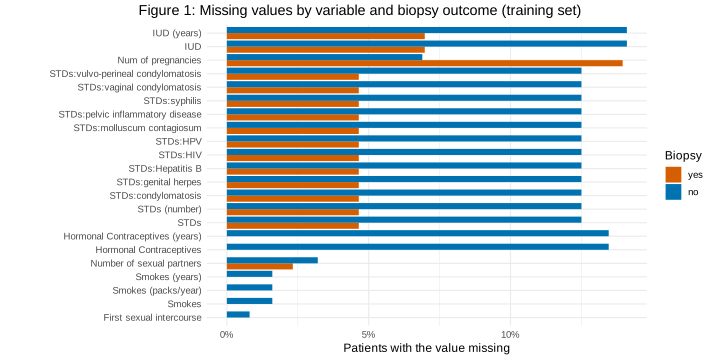

In [10]:
  # Missingness by variable and outcome -> motivates median imputation + missing-value indicators
  options(repr.plot.width = 10, repr.plot.height = 5)
  train |>
    group_by(Biopsy) |>
    summarise(across(everything(), ~ mean(is.na(.x)))) |>
    pivot_longer(-Biopsy, names_to = "variable", values_to = "missing") |>
    group_by(variable) |>
    filter(any(missing > 0)) |>
    ungroup() |>
    ggplot(aes(missing, reorder(variable, missing), fill = Biopsy)) +
    geom_col(position = "dodge") +
    scale_fill_manual(values = outcome_colours) +
    scale_x_continuous(labels = scales::percent) +
    labs(x = "Patients with the value missing", y = NULL, fill = "Biopsy",
         title = "Figure 1: Missing values by variable and biopsy outcome (training set)") +
    theme_minimal(base_size = 12) + centre_title

In [11]:
  # Missingness patterns: questions go missing in whole blocks
  train |>
    mutate(pattern = case_when(
      is.na(STDs) & is.na(`Hormonal Contraceptives`) & is.na(IUD) ~ "STD, contraceptive and IUD sections all missing",
      is.na(STDs) ~ "STD section missing",
      is.na(`Hormonal Contraceptives`) | is.na(IUD) ~ "Contraceptive and/or IUD section missing",
      if_any(-Biopsy, is.na) ~ "Other single answers missing",
      TRUE ~ "Complete"
    )) |>
    group_by(Pattern = pattern) |>
    summarise(Patients = n(), `Positive biopsy (%)` = 100 * mean(Biopsy == "yes")) |>
    arrange(desc(Patients)) |>
    show_table("Table 2: Missingness patterns and the share of positive biopsies")


**Table 2: Missingness patterns and the share of positive biopsies**

|Pattern                                         | Patients| Positive biopsy (%)|
|:-----------------------------------------------|--------:|-------------------:|
|Complete                                        |      516|                 6.8|
|STD, contraceptive and IUD sections all missing |       74|                 0.0|
|Other single answers missing                    |       55|                 7.3|
|Contraceptive and/or IUD section missing        |       16|                12.5|
|STD section missing                             |        6|                33.3|

**Class Balance and Missing Values (Table 1, Figure 1 & Table 2)**

Only 43 of the 667 training patients (6.4%) had a positive biopsy (Table 1). Predicting "negative" for everyone yields 93.6% accuracy, motivating stratified splits and clinical net benefit rather than accuracy. Figure 1 and Table 2 show that missing values occur in whole questionnaire blocks rather than at random: none of the 74 patients who skipped the STD, contraceptive, and IUD sections together had a positive biopsy (0.0% vs. 6.8% among complete responders). Because skipping a section carries outcome signal, our preprocessing recipe adds a **missing-value indicator** for each variable alongside **median imputation**.

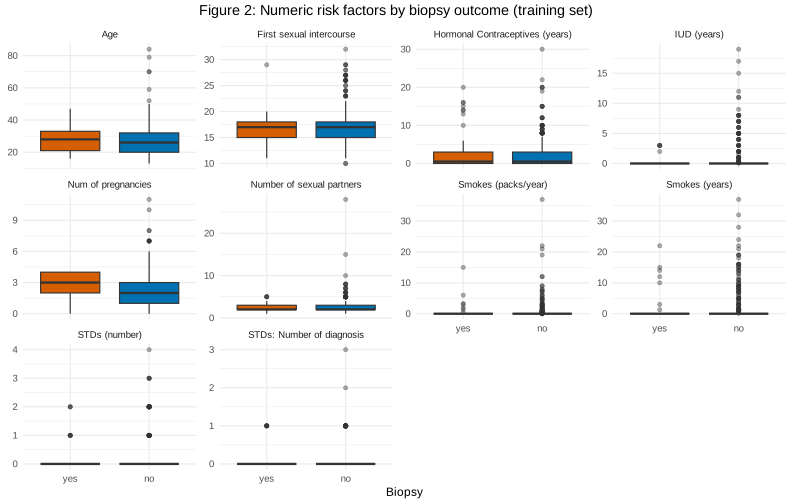

In [13]:
  # Distributions of numeric variables -> skewness and outliers motivate median imputation and standardisation
  binary_vars <- train |>
    select(-Biopsy) |>
    select(where(~ n_distinct(na.omit(.x)) <= 2)) |>
    names()
  numeric_vars <- setdiff(names(train), c(binary_vars, "Biopsy"))

  options(repr.plot.width = 11, repr.plot.height = 7)
  train |>
    select(all_of(numeric_vars), Biopsy) |>
    pivot_longer(-Biopsy, names_to = "variable") |>
    filter(!is.na(value)) |>
    ggplot(aes(Biopsy, value, fill = Biopsy)) +
    geom_boxplot(outlier.alpha = 0.4, show.legend = FALSE) +
    scale_fill_manual(values = outcome_colours) +
    facet_wrap(~ variable, scales = "free_y", ncol = 4) +
    labs(x = "Biopsy", y = NULL,
         title = "Figure 2: Numeric risk factors by biopsy outcome (training set)") +
    theme_minimal(base_size = 12) +
    theme(plot.title = element_text(hjust = 0.5), plot.title.position = "plot")   # centre the title

**Distributions of Numeric Risk Factors (Figure 2)**

Figure 2 shows two key patterns across the 10 numeric predictors ($N = 667$):
1. **Severe Right-Skewness and Outliers:** Exposure duration and count variables (`Hormonal Contraceptives (years)`, `IUD (years)`, `Smokes (years)`, `Smokes (packs/year)`, `STDs (number)`, and `STDs: Number of diagnosis`) are heavily zero-inflated with extreme upper outliers (up to 30 contraceptive years and 37 smoking years/packs).
2. **Overlapping Baseline Demographics:** `Age`, `First sexual intercourse`, `Num of pregnancies`, and `Number of sexual partners` overlap substantially between groups, with slightly higher median parity (3 vs. 2) and age among positive cases.

Heavy skewness and outliers justify **median imputation** over mean imputation, while wide scale differences (e.g., `Age` 13–84 vs. `STDs: Number of diagnosis` 0–3) motivate **standardisation** for distance-based kernels (GPC) and shrinkage penalties (elastic net).

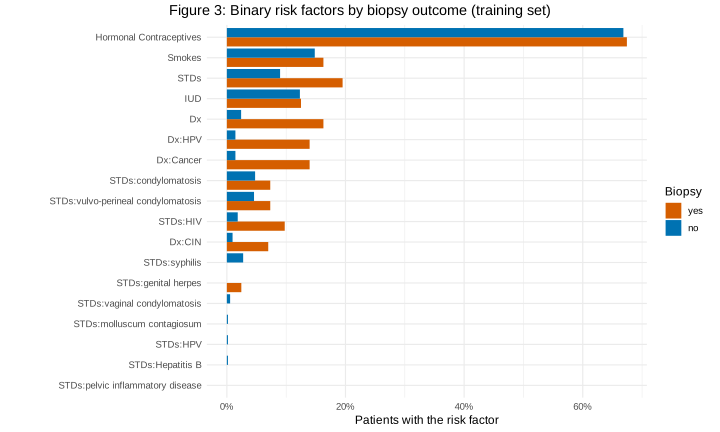

In [14]:
  # Binary risk factors -> very rare factors carry little information on their own
  options(repr.plot.width = 10, repr.plot.height = 6)
  train |>
    select(all_of(binary_vars), Biopsy) |>
    pivot_longer(-Biopsy, names_to = "variable") |>
    group_by(variable, Biopsy) |>
    summarise(share = mean(value, na.rm = TRUE), .groups = "drop") |>
    ggplot(aes(share, reorder(variable, share), fill = Biopsy)) +
    geom_col(position = "dodge") +
    scale_fill_manual(values = outcome_colours) +
    scale_x_continuous(labels = scales::percent) +
    labs(x = "Patients with the risk factor", y = NULL, fill = "Biopsy",
         title = "Figure 3: Binary risk factors by biopsy outcome (training set)") +
    theme_minimal(base_size = 12) + centre_title

**Prevalence of Binary Risk Factors (Figure 3)**

* **Elevated Prior Diagnoses and STDs in Positive Cases:** While `Hormonal Contraceptives` is common in both groups (>65%), biopsy-positive patients have far higher rates of prior clinical diagnoses—`Dx` (16% vs. 2%), `Dx:HPV` and `Dx:Cancer` (14% vs. 1.5%), and `Dx:CIN` (7% vs. 1%)—and infectious history (`STDs` 20% vs. 9%, `STDs:HIV` 10% vs. 2%). `Smokes` (16% vs. 15%) and `IUD` (12%) differ minimally on their own.
* **Sparsity of Rare STD Subtypes:** Seven specific STD indicators each appear in at most 3% of training patients (`STDs:pelvic inflammatory disease` in none) (while `STDs:cervical condylomatosis` and `STDs:AIDS` are zero for all patients and dropped), motivating regularised models that resist overfitting rare flags.

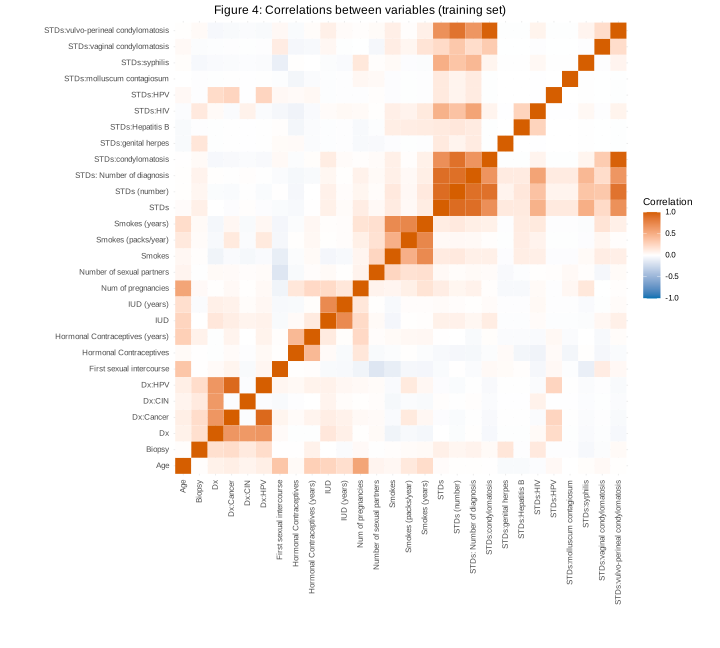

In [15]:
  # Correlations -> strongly correlated blocks motivate penalised regression (LASSO / elastic net)
  cor_mat <- train |>
    mutate(Biopsy = as.integer(Biopsy == "yes")) |>
    select(where(~ sd(.x, na.rm = TRUE) > 0)) |>
    cor(use = "pairwise.complete.obs")

  options(repr.plot.width = 10, repr.plot.height = 9)
  as_tibble(cor_mat, rownames = "var1") |>
    pivot_longer(-var1, names_to = "var2", values_to = "r") |>
    ggplot(aes(var1, var2, fill = r)) +
    geom_tile() +
    scale_fill_gradient2(low = "#0072B2", high = "#D55E00", limits = c(-1, 1)) +
    coord_fixed() +
    labs(x = NULL, y = NULL, fill = "Correlation",
         title = "Figure 4: Correlations between variables (training set)") +
    theme_minimal(base_size = 10) +
    theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5)) + centre_title

In [16]:
  # Weak individual links to the outcome -> motivates multivariable and non-linear models
  tibble(Variable = rownames(cor_mat), `Correlation with positive biopsy` = cor_mat[, "Biopsy"]) |>
    filter(Variable != "Biopsy") |>
    slice_max(abs(`Correlation with positive biopsy`), n = 8) |>
    show_table("Table 3: Variables most correlated with a positive biopsy", digits = 3)

**Table 3: Variables most correlated with a positive biopsy**

|Variable                        | Correlation with positive biopsy|
|:-------------------------------|--------------------------------:|
|Dx:Cancer                       |                            0.207|
|Dx:HPV                          |                            0.207|
|Dx                              |                            0.191|
|STDs:genital herpes             |                            0.151|
|STDs:HIV                        |                            0.132|
|Dx:CIN                          |                            0.128|
|STDs                            |                            0.091|
|Hormonal Contraceptives (years) |                            0.078|

**Inter-Predictor Correlations and Block Multicollinearity (Figure 4 & Table 3)**

As part of our exploratory data analysis, Pearson correlation was used to assess associations between predictors and biopsy outcomes. For binary-binary pairs, it is equivalent to the Phi coefficient, while for continuous-binary pairs, it corresponds to the point-biserial correlation.

* **Modest Univariate Linear Signal:** Individual predictors have weak marginal correlations with `Biopsy` (all $r \le 0.207$, led by `Dx:Cancer`, `Dx:HPV`, `Dx`, `STDs:genital herpes`, `STDs:HIV`, and `Dx:CIN`; Table 3), motivating multivariable and non-linear models (XGBoost, GPC, TabPFN, symbolic regression) that combine weak signals.
* **Block Multicollinearity:** Figure 4 reveals four tightly correlated diagonal blocks: (1) STDs, (2) Smoking binary/duration/pack-years, (3) Contraceptive binary/duration pairs, and (4) Prior Diagnoses (`Dx`, `Dx:Cancer`, `Dx:HPV`, `Dx:CIN`). This collinearity motivates elastic net regularisation and grouped permutation importance.


# Methods

## Data Pre-processing
Before the split, seven columns were removed. Hinselmann, Schiller and Cytology are diagnostic tests carried out alongside the biopsy: they would not be available when deciding whether to biopsy, and would leak the outcome. STDs:cervical condylomatosis and STDs:AIDS are zero for every patient, and the two 'time since STD diagnosis' columns are 92% missing. The 23 exact duplicate rows were also removed, leaving 835 patients and 28 predictors. These were split 80/20, stratified by biopsy outcome, into a training set (667 patients, 43 positive) and a test set (168 patients, 11 positive), which stayed locked until the final evaluation.

All preprocessing is defined as a single recipe that is re-fitted on the training portion of every cross-validation fold, so no information from validation or test data leaks into the models. Because missing answers carry information about the outcome (Table 2), each variable first receives a missing-value indicator (except for symbolic regression); missing values are then imputed with the median, which is robust to the skewed distributions and outliers in Figure 2, constant columns are removed, and all predictors are standardised so that penalised regression is not affected by differences in scale. The recipe turns the 28 original predictors into 49 and fills all 1,415 missing values. We tested SMOTE-NC oversampling but discarded it, as the synthetic positive patients lost the rare risk factors (e.g. Dx:HPV fell from 14% of positive patients to 0%) and every model performed worse than chance; class imbalance is instead handled through stratified folds, PR AUC for tuning, and net benefit at a 5% risk threshold as the primary criterion.


In [17]:
  # Step 10: preprocessing recipe
  # The recipe is only a plan: it is re-fitted on the training part of every CV fold (Step 13),
  # so medians and scaling never see the validation or test data.

  # Clean column names (e.g. "STDs:HIV" -> "stds_hiv") so every model and formula can use them
  make_clean_names <- function(x) gsub("^_|_$", "", gsub("[^a-z0-9]+", "_", tolower(x)))
  train_clean <- train |> rename_with(make_clean_names)

  make_recipe <- function(data, na_indicators = TRUE) {
    rec <- recipe(biopsy ~ ., data = data)
    if (na_indicators) {
      rec <- rec |> step_indicate_na(all_predictors())    # 1 = value was missing (Table 2: missingness is informative)
    }
    rec |>
      step_impute_median(all_numeric_predictors()) |>    # median: robust to the skew and outliers in Figure 2
      step_zv(all_predictors()) |>                        # drop columns that are constant (e.g. indicators with no NAs)
      step_normalize(all_numeric_predictors())            # standardise: needed by penalised regression and the GPC kernel
  }
  # No SMOTE-NC or class weights: SMOTE-NC erased rare risk factors from the synthetic positives and
  # made models worse than random; class weights gave no improvement. Class imbalance is handled by
  # stratified folds, average precision for tuning, and net benefit at a 5% threshold (Step 14-15).

## Evaluation Metrics
Because positive biopsies represent only 6.4% of the cohort, accuracy is uninformative. Our primary evaluation criterion is **net benefit at a 5% risk threshold** ($p_t = 0.05$) (Vickers & Elkin, 2006), which measures net true positives found per patient after penalising unnecessary biopsies in the same units:
$$NB = \frac{TP}{n} - \frac{FP}{n} \times \frac{p_t}{1 - p_t}$$
At $p_t = 5\%$, each false positive is weighted at $5/95 = 1/19$ of a true positive (finding one positive biopsy is worth up to 19 unnecessary biopsies). The threshold was set on clinical grounds and fixed before the test set was unlocked. A biopsy is a minor procedure, whereas a missed cancer or precancer is very costly, so a low threshold is appropriate. Clinical guidelines already recommend colposcopy, the examination at which biopsies are taken, when a patient's immediate risk of CIN 3+ is 4% or more (Perkins et al., 2020). A positive biopsy is a broader outcome than CIN 3+, so we use a slightly higher threshold of 5%. Net benefit is reported per 1,000 patients (maximum = prevalence, 64 per 1,000). A clinically useful model must beat both default strategies: **biopsying no one** ($NB = 0$) and **biopsying everyone** ($NB = \frac{43}{667} - \frac{624}{667} \times \frac{1}{19} \approx 0.0152$, or 15.2 per 1,000).

For a model, every patient whose predicted risk is at least $p_t$ counts as biopsied, and $TP$ and $FP$ are counted among those patients. The weight $p_t/(1-p_t)$ comes from decision theory. Choosing the threshold $p_t$ means that a patient whose risk is exactly $p_t$ is equally well off with or without a biopsy, so the harm of one unnecessary biopsy equals $p_t/(1-p_t)$ times the benefit of finding one positive biopsy (Vickers & Elkin, 2006). Repeating the calculation over a range of thresholds gives a decision curve (Figure 5), which shows whether a conclusion depends on the exact choice of 5%.

**Secondary metrics and selection.** Hyperparameters are tuned in inner CV using **PR AUC** (average precision; no-skill baseline = 0.064; Saito & Rehmsmeier, 2015), which evaluates the full ranking rather than a noisy single cut-off. We also report ROC AUC, and the sensitivity and specificity at 5%. Models are compared across 50 outer folds via the **corrected resampled $t$-test** with Holm adjustment (Nadeau & Bengio, 2003). The final model is chosen by the **one-standard-error (1-SE) rule** along a pre-specified simplicity order (elastic net, symbolic regression, GPC, XGBoost, TabPFN), checked for calibration, and evaluated once on the locked test set with 1,000 stratified bootstrap 95% CIs.

## Models
Five models from distinct families are compared on identical nested cross-validation splits (5 stratified outer folds $\times$ 10 repeats = 50 outer folds; 5-fold inner CV tuned on PR AUC; recipe re-fitted inside every split):

| Model | Family | Question it answers | Hyperparameters tuned |
| :--- | :--- | :--- | :--- |
| **Elastic net** | Penalised linear model | Which risk factors matter in a linear baseline? | Penalty $\lambda$, mixture $\alpha$ |
| **XGBoost** | Boosted decision trees | How much signal lies in non-linear interactions? | Tree depth, learning rate $\eta$ |
| **TabPFN** | Pretrained transformer | Can synthetic prior pretraining beat small-sample fits? | None |
| **Gaussian process** | Bayesian kernel method | Is risk driven by smooth similarity to known positives? | RBF kernel width $\sigma$ |
| **Symbolic regression** | Evolutionary search | Can biopsy risk be written as a short, readable equation? | Length penalty $\lambda$, max depth |


In [18]:
# Steps 11-13: shared set-up for the nested cross-validation of all five models
# Step 11: the model packages and the tuning metric (PR AUC, estimated by average precision)
# Install a package if it cannot be loaded (also catches a broken half-finished install after a runtime reset);
# not quiet, so a failed install shows its error here instead of later
model_pkgs <- c("gramEvol", "glmnet", "xgboost", "kernlab")
missing_model_pkgs <- model_pkgs[!vapply(model_pkgs, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing_model_pkgs))
     suppressMessages(install.packages(missing_model_pkgs, quiet = TRUE))
library(gramEvol)

stopifnot(nrow(train_clean) == 667, sum(train_clean$biopsy == "yes") == 43)   # Step 7 must use pool = 0

# PR AUC estimated by average precision (step-wise; a model that guesses at random scores the prevalence)
avg_precision <- function(score, y01) {
  o <- order(score, decreasing = TRUE)
  score <- score[o]; y01 <- y01[o]
  last <- c(score[-1] != score[-length(score)], TRUE)   # tied scores count as one step
  tp <- cumsum(y01)[last]; fp <- cumsum(1 - y01)[last]
  sum(diff(c(0, tp / sum(y01))) * tp / (tp + fp))
}
pr_auc <- function(truth, prob) avg_precision(prob, as.integer(truth == "yes"))

# Step 12: 5 stratified folds x 10 repeats = 50 outer folds, identical for every model
# pool = 0 forces stratification (positives are only 6.4%); rsample warns about this, so the warning is silenced
set.seed(4510)
outer_folds <- suppressWarnings(vfold_cv(train_clean, v = 5, repeats = 10, strata = biopsy, pool = 0))

# Step 13: nested cross-validation for one model (the two helper functions below, then run_nested_cv())
# Fits the recipe on the training part only, then applies it to both parts (no leakage)
bake_split <- function(train_part, new_part, na_indicators) {
  rec <- prep(make_recipe(train_part, na_indicators))
  list(train = bake(rec, NULL), new = bake(rec, new_part))
}

# Inner loop: try every setting on the inner folds, keep the best mean PR AUC,
# refit on the whole outer-training part and predict the outer-validation patients
tune_and_predict <- function(model, outer_train, outer_valid, inner_folds) {
  best <- tibble()
  if (nrow(model$grid) > 0) {
    inner <- map(inner_folds$splits, ~ bake_split(analysis(.x), assessment(.x), model$na_indicators))
    scores <- pmap_dbl(model$grid, function(...) {
      mean(map_dbl(inner, function(b) pr_auc(b$new$biopsy, model$fit_predict(b$train, b$new, ...))))
    })
    best <- model$grid[which.max(scores), ]
  }
  outer <- bake_split(outer_train, outer_valid, model$na_indicators)
  do.call(model$fit_predict, c(list(outer$train, outer$new), as.list(best)))
}

# run_nested_cv(): in each of the 50 outer folds, tunes on the inner folds, then predicts the outer-validation
# patients; returns the PR AUC and ROC AUC of every fold, the out-of-fold predictions and, for symbolic
# regression only, the chosen formulas
run_nested_cv <- function(model) {
  folds <- map(seq_len(nrow(outer_folds)), function(i) {
    s <- outer_folds$splits[[i]]
    set.seed(4510 + i)
    inner_folds <- suppressWarnings(vfold_cv(analysis(s), v = 5, strata = biopsy, pool = 0))
    prob <- tune_and_predict(model, analysis(s), assessment(s), inner_folds)
    truth <- assessment(s)$biopsy
    list(metrics = tibble(fold = i, pr_auc = pr_auc(truth, prob), roc_auc = roc_auc_vec(truth, prob),
                          n_pos = sum(truth == "yes")),
         preds = tibble(fold = i, row = complement(s), truth = truth, prob = as.numeric(prob)),
         formulas = if (!is.null(attr(prob, "formula")))   # symbolic regression only
           tibble(fold = i, formula = attr(prob, "formula"), vars = list(attr(prob, "vars"))))
  })
  map(c(metrics = "metrics", preds = "preds", formulas = "formulas"), ~ bind_rows(map(folds, .x)))
}


## Penalised Logistic Regression (Elastic Net)
Elastic net (Zou & Hastie, 2005) combines $L_1$ (LASSO) and $L_2$ (Ridge) penalties to shrink coefficients and handle correlated predictor blocks without arbitrarily dropping entire clusters:
$$\min_{\beta_0, \beta} \left[ -\frac{1}{N} \sum_{i=1}^N \left( y_i \log p(X_i) + (1 - y_i) \log(1 - p(X_i)) \right) + \lambda \left( \frac{1 - \alpha}{2} \|\beta\|_2^2 + \alpha \|\beta\|_1 \right) \right]$$
where $p(X_i) = (1 + e^{-(\beta_0 + \beta^T X_i)})^{-1}$.

**Settings and performance.** Fitted via `glmnet` on all 49 preprocessed predictors (`na_indicators = TRUE`), tuning $\lambda \in [10^{-4}, 10^0]$ (10 log-spaced values) and $\alpha \in \{0.2, 0.4, 0.6, 0.8\}$ via inner 5-fold CV on PR AUC. Elastic net provides an interpretable linear baseline that handles block collinearity, though its additive log-odds assumption cannot capture non-linear interactions. Across the 50 outer folds, it achieved a PR AUC of $0.205 \pm 0.115$ (3.2$\times$ the 0.064 baseline; Table 5) and an ROC AUC of $0.623 \pm 0.092$, but its net benefit at 5% fell below biopsying everyone.


In [19]:
# Model 1: penalised logistic regression (elastic net, glmnet)
# run_nested_cv() has already applied the recipe (imputation, missing-value indicators, standardisation)
# to `train` and `new`, so the model is fitted directly on the preprocessed data.
suppressPackageStartupMessages(library(glmnet))   # hide the start-up messages

model_enet <- list(
  grid = expand_grid(
    penalty = 10^seq(-4, 0, length.out = 10),   # lambda: overall penalty strength
    mixture = c(0.2, 0.4, 0.6, 0.8)             # alpha: 0 = ridge, 1 = LASSO
  ),
  na_indicators = TRUE,
  fit_predict = function(train, new, penalty, mixture) {
    fit <- logistic_reg(penalty = penalty, mixture = mixture) |>
      set_engine("glmnet") |>
      fit(biopsy ~ ., data = train)
    predict(fit, new, type = "prob")$.pred_yes
  }
)

# Run nested cross-validation: 5 outer folds x 10 repeats
cv_enet <- run_nested_cv(model_enet)

# Check all 50 outer evaluations completed successfully
stopifnot(nrow(cv_enet$metrics) == 50, all(cv_enet$metrics$n_pos %in% c(8, 9)))


## Extreme Gradient Boosting (XGBoost)
XGBoost (Chen & Guestrin, 2016) sequentially builds regression trees $f_k \in \mathcal{F}$ to minimise a regularised second-order Taylor approximation of the logistic loss:
$$\mathcal{L} = \sum_{i=1}^n l(y_i, \hat{p}_i) + \sum_{k=1}^K \Omega(f_k), \quad \hat{y}_i^{(t)} = \hat{y}_i^{(t-1)} + \eta f_t(X_i), \quad \hat{p}_i = \frac{1}{1 + e^{-\hat{y}_i}}$$
where $\Omega(f_k)$ penalises tree complexity and $\eta$ is the learning rate.

**Training and prediction.** Training adds one tree per round, for 300 rounds. In each round, every training patient gets the gradient $g_i = \hat{p}_i - y_i$ and the curvature $h_i = \hat{p}_i(1 - \hat{p}_i)$ of the logistic loss at the current prediction. The new tree is grown greedily, up to the tuned maximum depth: each split is the one with the largest gain
$$\text{Gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right] - \gamma,$$
where $G$ and $H$ are the sums of $g_i$ and $h_i$ over the patients in the left ($L$) and right ($R$) branches. Each leaf then gets the weight $w = -G/(H + \lambda)$. Both formulas follow from the penalty $\Omega(f) = \gamma T + \frac{1}{2}\lambda\|w\|^2$ for a tree with $T$ leaves (xgboost defaults: $\lambda = 1$, $\gamma = 0$). The new tree's weights are multiplied by $\eta$ before it is added, and each round uses a random 80% of the patients. To predict, a patient's log-odds $\hat{y}$ is a starting value plus the weights of the leaves that the patient falls into in all 300 trees, and the predicted risk is $\hat{p} = 1/(1 + e^{-\hat{y}})$.

**Settings and performance.** Trained for 300 rounds with 80% subsampling on all 49 preprocessed features, tuning maximum tree depth $\in \{2, 4\}$ and learning rate $\eta \in \{0.03, 0.1\}$ via inner 5-fold CV. XGBoost captures non-linear thresholds and interactions, though with only 34–35 positives in each outer-training fold its predictions are unstable, and it is less interpretable than a linear model. Across the 50 outer folds, XGBoost achieved the highest mean PR AUC ($0.279 \pm 0.119$, 4.4$\times$ baseline; Table 5) and ROC AUC ($0.719 \pm 0.090$).










In [20]:
# Model 2: XGBoost
library(xgboost)

# Boosted decision trees. run_nested_cv() has already applied the recipe, so the model is fitted directly
# on the preprocessed data. Tuned: tree depth and learning rate. Fixed: 300 rounds, each tree grown on a
# random 80% of the patients (subsample = 0.8).
model_xgb <- list(
  grid = expand_grid(
    tree_depth = c(2, 4),
    learn_rate = c(0.03, 0.1)
  ),

  na_indicators = TRUE,

  fit_predict = function(train, new, tree_depth, learn_rate) {

    x_train <- select(train, -biopsy)
    x_new <- select(new, -biopsy)

    y_train <- as.integer(train$biopsy == "yes")

    dtrain <- xgb.DMatrix(
      data = as.matrix(x_train),
      label = y_train
    )
    dnew <- xgb.DMatrix(data = as.matrix(x_new))

    fit <- xgb.train(
      params = list(
        objective = "binary:logistic",
        eval_metric = "aucpr",
        max_depth = tree_depth,
        eta = learn_rate,
        subsample = 0.8
      ),
      data = dtrain,
      nrounds = 300,
      verbose = 0
    )

    predict(fit, dnew)
  }
)

# Run nested cross-validation: 5 outer folds x 10 repeats
cv_xgb <- run_nested_cv(model_xgb)

# Check all 50 outer evaluations completed
stopifnot(
  nrow(cv_xgb$metrics) == 50,
  all(cv_xgb$metrics$n_pos %in% c(8, 9))
)

## TabPFN
TabPFN v2 (Hollmann et al., 2025) is a transformer pretrained on ~130 million synthetic tabular datasets generated from random structural causal models. At inference, its weights are frozen: it reads the training patients $D$ as context and approximates the Bayesian posterior predictive distribution $p(y \mid x, D) = \int p(y \mid x, \phi) p(\phi \mid D)\,d\phi$ , where $\phi$ is a data-generating mechanism drawn from the prior (Müller et al., 2022). The default classifier averages 8 forward passes, each with a shuffled feature order and permuted class labels.

**Training and prediction.** All of TabPFN's training happened before we used it. In pretraining, each synthetic dataset was split into a training part and a test part. The network saw the training rows with their labels and predicted the labels of the test rows, and its weights were updated to reduce the cross-entropy of these predictions. A network that does this well over millions of datasets approximates the posterior predictive distribution above (Müller et al., 2022). On our data, `fit()` changes no weights: it only prepares and stores the training patients. To predict, the training patients, with their biopsy results, and the patients to be predicted pass through the network together as one table. Each layer applies attention in two directions, across the risk factors of each patient and across the patients for each risk factor, and the patients to be predicted attend only to the training patients. The training patients are therefore the context from which the network infers how the risk factors relate to the biopsy result, and the output is the probability of each outcome.

**Settings and performance.** Applied with default v2 weights (`tabpfn 9.2.0` via `reticulate`, no inner tuning needed) across all 49 preprocessed features. Pretrained tabular priors are well suited to small cohorts (~533 training patients, ~34 positives per fold), though the model is a black box with $\mathcal{O}(N^2)$ attention scaling. Across the 50 outer folds, TabPFN achieved a PR AUC of $0.258 \pm 0.127$ (Table 5) and an ROC AUC of $0.708 \pm 0.103$.





In [21]:
  # Model 3: TabPFN v2 (pretrained transformer; Python package tabpfn, called from R through reticulate)
  # fit() updates no weights: it only stores the training patients, and forward passes of the pretrained
  # network (8, averaged) give P(positive biopsy) for each new patient. No hyperparameters, so no inner loop.
  suppressMessages(install.packages(setdiff("reticulate", rownames(installed.packages())), quiet = TRUE))
  python <- Sys.which("python3")
  Sys.setenv(RETICULATE_PYTHON = python, HF_HUB_VERBOSITY = "error",           # keep download messages
             HF_HUB_DISABLE_PROGRESS_BARS = "1")                               # out of the output
  stopifnot(system2(python, c("-m", "pip", "install", "-q", "tabpfn==9.2.0"), stdout = FALSE, stderr = FALSE) == 0)
  library(reticulate)
  tabpfn <- import("tabpfn")
  tabpfn_v2 <- import("tabpfn.constants")$ModelVersion$V2   # v2 weights are public (later versions need a login)
  import("warnings")$filterwarnings("ignore")                # e.g. "running on CPU may be slow"

  model_tabpfn <- list(
    grid = tibble(),                 # nothing to tune
    na_indicators = TRUE,            # same inputs as elastic net, XGBoost and the GPC
    fit_predict = function(train, new) {
      clf <- tabpfn$TabPFNClassifier$create_default_for_version(tabpfn_v2, device = "cpu", random_state = 4510L)
      clf$fit(as.matrix(select(train, -biopsy)), array(as.integer(train$biopsy == "yes")))
      clf$predict_proba(as.matrix(select(new, -biopsy)))[, 2]   # classes are sorted (0, 1): column 2 = P(yes)
    }
  )

  cv_tabpfn <- run_nested_cv(model_tabpfn)   # 50 outer folds; about 20-40 minutes on Colab
  stopifnot(nrow(cv_tabpfn$metrics) == 50, all(cv_tabpfn$metrics$n_pos %in% c(8, 9)))

## Gaussian Process Classifier
A Gaussian Process Classifier (GPC) (Rasmussen & Williams, 2006) places a zero-mean GP prior over smooth latent functions of the risk factors passed through a logistic link:
$$\log \frac{p(X)}{1 - p(X)} = f(X), \quad f(X) \sim \mathcal{GP}(0, k(X, X')), \quad k(X, X') = \exp(-\sigma \|X - X'\|^2)$$
The logistic likelihood gives no closed-form posterior, so `kernlab::gausspr` (Karatzoglou et al., 2004) finds the most likely latent function (the posterior mode, on which the Laplace approximation is centred) and predicts from it. It does not average over the uncertainty in $f(X)$: the protection against overfitting the few positives comes from the Gaussian process prior, which acts as a smoothness penalty.

**Training and prediction.** `kernlab` writes the latent function as a weighted sum of kernel similarities to the $n$ training patients, $f(X) = \sum_{i=1}^{n} \alpha_i k(X, X_i)$. Training finds the posterior mode by Newton iterations, updating the weights $\alpha_i$ until the gradient is close to zero. To predict, a new patient's latent value is the same weighted sum of its similarities to the training patients, $f(X_*) = \sum_{i=1}^{n} \alpha_i k(X_*, X_i)$, and the predicted risk is $1/(1 + e^{-f(X_*)})$. The kernel parameter $\sigma$ sets how quickly the similarity falls with distance: a small $\sigma$ gives a smooth risk surface shaped by many patients, and a large $\sigma$ gives one shaped by each patient's nearest neighbours.


**Settings and performance.** The inverse RBF kernel width $\sigma \in \{0.0005, 0.002, 0.01, 0.05, 0.2\}$ is tuned by inner 5-fold CV across all 49 standardised predictors. While GPC outputs smooth probabilities directly, its isotropic Euclidean distance weights all 49 coordinates equally, allowing noisy missingness flags to dilute rare high-signal diagnoses (`Dx:HPV`, `Dx:Cancer`). Across 50 outer folds, GPC achieved a PR AUC of $0.180 \pm 0.084$ (Table 5) and an ROC AUC of $0.623 \pm 0.106$.

In [22]:
# Model 4: Gaussian process classifier (RBF kernel, kernlab::gausspr)
# run_nested_cv() has already applied the recipe, so the model is fitted directly on the preprocessed data.
# Tuned: sigma, the inverse width of the RBF kernel (small sigma = a smooth risk surface shaped by many patients).
model_gpc <- list(
  grid = tibble(sigma = c(0.0005, 0.002, 0.01, 0.05, 0.2)),
  na_indicators = TRUE,
  fit_predict = function(train, new, sigma) {
    fit <- kernlab::gausspr(
      as.matrix(select(train, -biopsy)),
      train$biopsy,
      kernel = "rbfdot",
      kpar = list(sigma = sigma),
      type = "classification"
    )
    kernlab::predict(fit, as.matrix(select(new, -biopsy)), type = "probabilities")[, "yes"]
  }
)

cv_gpc <- run_nested_cv(model_gpc)
stopifnot(nrow(cv_gpc$metrics) == 50, all(cv_gpc$metrics$n_pos %in% c(8, 9)))


## Symbolic Regression
Symbolic regression (Koza, 1992) uses grammatical evolution (`gramEvol`; O'Neill & Ryan, 2001; Noorian et al., 2016) to evolve a short mathematical formula $f(X_1, \dots, X_p)$ from standardised risk factors, constants $\{0.5, 1, 2\}$, and operators $\{+, -, \times\}$, converted to probabilities via logistic regression $\log \frac{p(X)}{1 - p(X)} = a + b f(X)$. Unlike regression, which fixes the form of the equation and estimates only its coefficients, symbolic regression searches for the form itself.

**How the formula is found.** An evolutionary algorithm searches by imitating natural selection. It keeps a set of candidate solutions, scores each one with a fitness function, and builds new candidates from the best ones by mutation (small random changes) and, in genetic algorithms, crossover (combining parts of two parents), generation after generation. In grammatical evolution, a candidate is a list of integers (a genome) that the grammar turns into a formula. Reading the integers from left to right, each one chooses which rule replaces the next unfinished part of the formula, for example whether an expression becomes 'expression operator expression', a variable or a constant. Every genome therefore gives a valid formula. For a single formula, `gramEvol` uses an evolution strategy: each generation keeps the best formula found so far and adds mutated copies of it and new random formulas. Because our grammar is recursive, `gramEvol`'s default setting makes all 60 candidates of each generation new random formulas, with no mutated copies. The search therefore compared 60 new formulas in each of 60 generations (3,600 in total) and kept the best one. Each formula is scored by its training average precision, the project's tuning metric, in place of the squared error used in standard symbolic regression, minus a length penalty that keeps formulas short: $AP(f) - \lambda |f|$. To predict, the chosen formula is computed for each new patient, and $a$ and $b$, fitted by logistic regression on the training patients, turn it into a risk.

**Settings and performance.** Missing-value indicators are excluded so formulas contain only clinical risk factors, tuning $\lambda \in \{0.002, 0.01\}$ and maximum depth $\in \{3, 5\}$. Across 50 outer folds, hormonal contraceptive years (29/50 formulas), `Dx:HPV` (22), and `Dx:Cancer` (16) appeared most frequently. The first is consistent with the known association between long-term hormonal contraceptive use and cervical cancer (Smith et al., 2003). Table 4 lists the formulae chosen in more than one fold. The most common, chosen in 9 of the 50 folds, was simply $f$ = `Hormonal Contraceptives (years)` + `Dx:HPV`; the same formula with `Dx:Cancer` in place of `Dx:HPV` was chosen in 7 more, and 35 of the 50 formulas use exactly two variables. Because $a$ and $b$ are refitted for every formula, formulas that differ only by a constant or a factor give the same predictions: two more folds chose such variants of the most common formula, $2 \times$ (`Hormonal Contraceptives (years)` + `Dx:HPV`) and `Hormonal Contraceptives (years)` $-$ (1 $-$ `Dx:HPV`). Biopsy risk can therefore be written as a short, readable equation, but not an accurate one. Because rare binary indicators isolate only a few positives while ranking most patients near chance, symbolic regression achieved a PR AUC of $0.150 \pm 0.094$ (Table 5) and an ROC AUC of $0.521 \pm 0.106$.






In [23]:
# Model 5: symbolic regression (grammatical evolution, gramEvol)
# Evolves a formula f from the predictors, the constants 0.5, 1, 2 and the operations + - *,
# scored by average precision minus a length penalty; then log-odds = a + b * f by logistic regression.
sr_scores <- function(expr, x) {
  s <- tryCatch(suppressWarnings(eval(expr, as.list(x))), error = function(e) NA_real_)
  if (length(s) == 1) s <- rep(s, nrow(x))   # a formula without variables is a constant
  s
}
model_sr <- list(
  grid = expand_grid(penalty = c(0.002, 0.01), max_depth = c(3, 5)),
  na_indicators = FALSE,                      # formulas use actual risk factors only
  fit_predict = function(train, new, penalty, max_depth) {
    x <- select(train, -biopsy)
    y01 <- as.integer(train$biopsy == "yes")
    grammar <- CreateGrammar(list(
      expr  = grule(op(expr, expr), var, var, const),
      op    = grule(`+`, `-`, `*`),
      var   = do.call(grule, lapply(names(x), as.name)),
      const = grule(0.5, 1, 2)))
    fitness_cost <- function(expr) {          # minimised: -AP + penalty x length
      s <- sr_scores(expr, x)
      if (anyNA(s) || !all(is.finite(s))) return(Inf)
      -avg_precision(s, y01) + penalty * length(all.names(expr))
    }
    best <- GrammaticalEvolution(grammar, fitness_cost, max.depth = max_depth, iterations = 60,
                                 popSize = 60, disable.warnings = TRUE)$best$expressions
    s <- sr_scores(best, x)
    ab <- coef(suppressWarnings(glm(y01 ~ s, family = binomial)))   # a and b in log-odds = a + b * f
    ab[is.na(ab)] <- 0
    s_new <- sr_scores(best, select(new, -biopsy))
    s_new[!is.finite(s_new)] <- 0
    structure(plogis(ab[[1]] + ab[[2]] * s_new),
              formula = paste(deparse(best[[1]]), collapse = ""), vars = intersect(all.vars(best), names(x)))
  }
)

cv_sr <- run_nested_cv(model_sr)   # 50 outer folds; takes about 1.5-2 hours on Colab
stopifnot(nrow(cv_sr$metrics) == 50, all(cv_sr$metrics$n_pos %in% c(8, 9)))

# Table 4: the formulae themselves; a sum counts once whatever the order of its terms (a + b = b + a)
sort_sum <- function(s) if (grepl("[-*]", s)) s else paste(sort(trimws(strsplit(s, "+", fixed = TRUE)[[1]])), collapse = " + ")
sr_counts <- cv_sr$formulas |>
  mutate(formula = map_chr(formula, sort_sum)) |>
  count(formula, sort = TRUE)
sr_counts |>
  filter(n >= 2) |>
  transmute(`Formula f` = formula, `Folds choosing it (of 50)` = n) |>
  show_table(sprintf("Table 4: Formulae found by symbolic regression (chosen in 2 or more of the 50 outer folds; %d others were chosen once each)",
                     sum(sr_counts$n == 1)), digits = 0)

**Table 4: Formulae found by symbolic regression (chosen in 2 or more of the 50 outer folds; 23 others were chosen once each)**

|Formula f                                           | Folds choosing it (of 50)|
|:---------------------------------------------------|-------------------------:|
|dx_hpv + hormonal_contraceptives_years              |                         9|
|dx_cancer + hormonal_contraceptives_years           |                         7|
|dx_hpv - number_of_sexual_partners                  |                         4|
|hormonal_contraceptives_years + stds_genital_herpes |                         3|
|dx_cancer - number_of_sexual_partners               |                         2|
|smokes_years + stds_hiv                             |                         2|

In [24]:
# Save the nested CV results of all five models (out-of-fold predictions, metrics, SR formulas),
# so Steps 14-25 can reload them after a runtime reset instead of re-running the 50 folds
cv_all <- list(enet = cv_enet, xgb = cv_xgb, tabpfn = cv_tabpfn, gpc = cv_gpc, sr = cv_sr)
saveRDS(cv_all, "cv_results_5_models.rds")


# Results



## Overall Findings and Optimal Model Selection

All results in this section come from the saved out-of-fold predictions of the 50 outer folds, so no model was refitted.

**Interpretation Guide for Table 5.** Net benefit counts the positive biopsies a strategy finds per 1,000 patients, minus 1/19 for every unnecessary biopsy. Biopsying no one scores 0 and biopsying everyone scores 15.2. A model beats biopsying everyone only if the unnecessary biopsies it avoids, divided by 19, outnumber the positive biopsies it misses. The highest possible value is 64, the number of positive patients per 1,000. PR AUC measures how well a model ranks positive patients above negative ones across all thresholds; ranking at random scores 0.064. Sensitivity is the share of positive biopsies whose predicted risk is 5% or more, and specificity is the share of negative patients below 5%, who would be spared a biopsy.

**Net benefit (Table 5, Figure 5).** TabPFN (24.9 per 1,000 patients) and XGBoost (23.4) gave the highest net benefit, well above biopsying everyone (15.2). Both beat biopsying everyone in 42 of the 50 folds. Elastic net (13.5), the Gaussian process classifier (12.7) and symbolic regression (9.7) were below biopsying everyone, so at this threshold they would do more harm than simply biopsying every patient. TabPFN and XGBoost have the highest net benefit at every threshold from 5% to 15% (Figure 5). Below about 4%, every model is within about 2 per 1,000 of biopsying everyone, so none adds a useful benefit.

**Classification at 5% (Table 5).** At the 5% threshold, XGBoost found 60% of positive biopsies (sensitivity 0.600) and correctly cleared 69% of negatives (specificity 0.689). TabPFN found 56% and cleared 77%. The other three models flagged most patients as high risk, with specificities of 0.44 or lower.

**Statistical comparison.** No difference in net benefit was significant after the corrected t-test and Holm adjustment (Nadeau & Bengio, 2003); the smallest adjusted p-value was 0.263. The advantage of TabPFN and XGBoost over biopsying everyone (9.7 and 8.2 per 1,000) was also not significant (adjusted p = 0.849 and 1.000). With only 43 positive biopsies in the training set, these differences cannot be confirmed statistically.

**Model selection.** TabPFN had the highest mean net benefit (24.9, corrected SE 5.8), so any model scoring at least 19.1 is within one standard error. XGBoost (23.4) is within this range and comes before TabPFN in the simplicity order fixed in advance (elastic net, symbolic regression, Gaussian process classifier, XGBoost, TabPFN), and its mean net benefit is higher than biopsying everyone. **XGBoost is therefore selected as the final model.**


In [25]:
# Step 14: net benefit at a 5% risk threshold in each of the 50 outer folds
# Net benefit = TP/n - FP/n x pt/(1 - pt): true positives found per patient, minus false positives
# weighted by the odds of the threshold (at 5%, one missed positive biopsy is worth 19 unnecessary biopsies)
if (!exists("cv_all")) cv_all <- readRDS("cv_results_5_models.rds")   # after a runtime reset
model_names <- c(enet = "Elastic net", xgb = "XGBoost", tabpfn = "TabPFN",
                 gpc = "Gaussian process classifier", sr = "Symbolic regression")
p_t <- 0.05

net_benefit <- function(truth, prob, pt) {
  pos <- prob >= pt
  (sum(pos & truth == "yes") - sum(pos & truth == "no") * pt / (1 - pt)) / length(truth)
}
nb_all <- function(truth, pt) mean(truth == "yes") - mean(truth == "no") * pt / (1 - pt)   # biopsy everyone

# All out-of-fold predictions in one table; folds 1-5 are repeat 1, folds 6-10 repeat 2, ...
oof <- imap_dfr(cv_all, ~ mutate(.x$preds, model = .y)) |>
  mutate(repeat_id = (fold - 1) %/% 5 + 1)

nb_folds <- oof |>
  group_by(model, fold) |>
  summarise(nb = net_benefit(truth, prob, p_t), nb_all = nb_all(truth, p_t), .groups = "drop")

model_order <- nb_folds |> group_by(model) |> summarise(m = mean(nb)) |> arrange(desc(m)) |> pull(model)   # best first


**Table 5: Net benefit at the 5% risk threshold and secondary metrics (50 outer folds; sensitivity and specificity: mean of 10 repeats; no-skill PR AUC = 0.064)**

|Strategy                    |Net benefit per 1,000 patients (mean ± SD) |Folds beating biopsy everyone (of 50) |PR AUC (mean ± SD) |Sensitivity at 5% |Specificity at 5% |
|:---------------------------|:------------------------------------------|:-------------------------------------|:------------------|:-----------------|:-----------------|
|TabPFN                      |24.9 ± 11.1                                |42                                    |0.258 ± 0.127      |0.560             |0.773             |
|XGBoost                     |23.4 ± 11.9                                |42                                    |0.279 ± 0.119      |0.600             |0.689             |
|Elastic net                 |13.5 ± 10.4                                |23                                    |0.205 ± 0.115      |0.637             |0.440             |
|Gaussian process classifier |12.7 ± 7.6                                 |27                                    |0.180 ± 0.084      |0.849             |0.146             |
|Symbolic regression         |9.7 ± 10.5                                 |18                                    |0.150 ± 0.094      |0.660             |0.332             |
|Biopsy everyone             |15.2 ± 3.5                                 |–                                     |–                  |1.000             |0.000             |
|Biopsy no one               |0.0 ± 0.0                                  |–                                     |–                  |0.000             |1.000             |

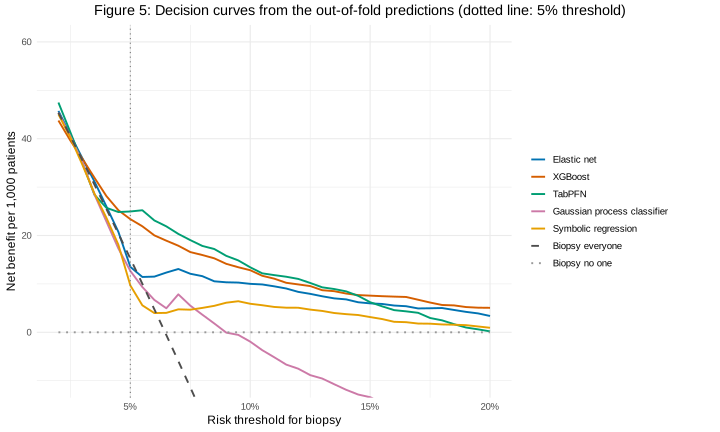

In [26]:
# Step 15: classification metrics at the 5% threshold, and the decision curve from 2% to 20%
# Each patient appears once in every repeat, so predictions are pooled within each repeat
# (all 667 patients) and the 10 repeats are then averaged
metrics_at <- function(truth, prob, pt) {
  pos <- prob >= pt
  tp <- sum(pos & truth == "yes"); fp <- sum(pos & truth == "no"); fn <- sum(!pos & truth == "yes")
  tn <- sum(!pos & truth == "no")
  prec <- if (tp + fp > 0) tp / (tp + fp) else NA_real_
  rec <- tp / (tp + fn)
  f_beta <- function(b) if (is.na(prec) || prec + rec == 0) 0 else (1 + b^2) * prec * rec / (b^2 * prec + rec)
  tibble(sensitivity = rec, specificity = tn / (tn + fp), precision = prec, f1 = f_beta(1), f2 = f_beta(2))
}

# Table 5: net benefit (primary) with PR AUC, sensitivity and specificity at 5% (secondary), all strategies
at_5 <- oof |>
  group_by(model, repeat_id) |>
  summarise(metrics_at(truth, prob, p_t), .groups = "drop_last") |>
  summarise(sensitivity = mean(sensitivity), specificity = mean(specificity))
pr_folds <- imap_dfr(cv_all, ~ tibble(model = .y, pr_mean = mean(.x$metrics$pr_auc), pr_sd = sd(.x$metrics$pr_auc)))
nb_everyone <- filter(nb_folds, model == "enet")$nb_all   # the same in every model's folds

nb_folds |>
  group_by(model) |>
  summarise(mean_nb = mean(nb), sd_nb = sd(nb), wins = sum(nb > nb_all)) |>
  left_join(pr_folds, by = "model") |>
  left_join(at_5, by = "model") |>
  arrange(desc(mean_nb)) |>
  transmute(Strategy = model_names[model],
            `Net benefit per 1,000 patients (mean ± SD)` = sprintf("%.1f ± %.1f", 1000 * mean_nb, 1000 * sd_nb),
            `Folds beating biopsy everyone (of 50)` = as.character(wins),
            `PR AUC (mean ± SD)` = sprintf("%.3f ± %.3f", pr_mean, pr_sd),
            `Sensitivity at 5%` = sprintf("%.3f", sensitivity),
            `Specificity at 5%` = sprintf("%.3f", specificity)) |>
  bind_rows(tibble(Strategy = c("Biopsy everyone", "Biopsy no one"),
                   `Net benefit per 1,000 patients (mean ± SD)` =
                     c(sprintf("%.1f ± %.1f", 1000 * mean(nb_everyone), 1000 * sd(nb_everyone)), "0.0 ± 0.0"),
                   `Folds beating biopsy everyone (of 50)` = "–",
                   `PR AUC (mean ± SD)` = "–",
                   `Sensitivity at 5%` = c("1.000", "0.000"),
                   `Specificity at 5%` = c("0.000", "1.000"))) |>
  show_table(sprintf("Table 5: Net benefit at the 5%% risk threshold and secondary metrics (50 outer folds; sensitivity and specificity: mean of 10 repeats; no-skill PR AUC = %.3f)",
                     mean(oof$truth[oof$model == "enet"] == "yes")))


# Decision curve: net benefit of each model and of the two default strategies across thresholds
thresholds <- seq(0.02, 0.20, by = 0.005)
dca <- oof |>
  group_by(model, repeat_id) |>
  reframe(pt = thresholds, nb = map_dbl(thresholds, \(t) net_benefit(truth, prob, t)),
          nb_all = map_dbl(thresholds, \(t) nb_all(truth, t))) |>
  group_by(model, pt) |>
  summarise(nb = mean(nb), nb_all = mean(nb_all), .groups = "drop")

options(repr.plot.width = 10, repr.plot.height = 6)
bind_rows(
  dca |> transmute(Strategy = model_names[model], pt, nb),
  dca |> filter(model == "enet") |> transmute(Strategy = "Biopsy everyone", pt, nb = nb_all),
  tibble(Strategy = "Biopsy no one", pt = thresholds, nb = 0)
) |>
  mutate(Strategy = factor(Strategy, levels = c(model_names, "Biopsy everyone", "Biopsy no one"))) |>
  ggplot(aes(pt, 1000 * nb, colour = Strategy, linetype = Strategy)) +
  geom_line(linewidth = 0.9) +
  geom_vline(xintercept = p_t, colour = "grey50", linetype = "dotted") +
  scale_colour_manual(values = c("#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "grey30", "grey60")) +
  scale_linetype_manual(values = c(rep("solid", 5), "dashed", "dotted")) +
  scale_x_continuous(labels = scales::percent) +
  coord_cartesian(ylim = c(-10, 60)) +
  labs(x = "Risk threshold for biopsy", y = "Net benefit per 1,000 patients", colour = NULL, linetype = NULL,
       title = "Figure 5: Decision curves from the out-of-fold predictions (dotted line: 5% threshold)") +
  theme_minimal(base_size = 12) + centre_title


In [27]:
# Step 16: corrected paired t-tests on net benefit at 5% (Nadeau & Bengio, 2003)
# The 50 folds share training patients, so the variance of the mean difference is inflated by
# (1/50 + n_test/n_train), with n_test/n_train = 1/4 for 5-fold CV; Holm adjustment over all 15 tests
corrected_t <- function(d) {
  se <- sd(d) * sqrt(1 / length(d) + 1 / 4)
  tibble(diff = mean(d), se = se, p = 2 * pt(-abs(mean(d) / se), df = length(d) - 1))
}
nb_wide <- nb_folds |>
  select(fold, model, nb) |>
  pivot_wider(names_from = model, values_from = nb) |>
  left_join(distinct(nb_folds, fold, nb_all), by = "fold")

pairs <- bind_rows(
  combn(names(model_names), 2, simplify = FALSE) |> map_dfr(\(p) tibble(a = p[1], b = p[2])),
  tibble(a = names(model_names), b = "nb_all")
)
t_tests <- pairs |>
  mutate(res = map2(a, b, \(x, y) corrected_t(nb_wide[[x]] - nb_wide[[y]]))) |>
  unnest(res) |>
  mutate(p_holm = p.adjust(p, method = "holm"))


In [28]:
# Step 17: choose the final model by net benefit with the one-standard-error rule
# Simplicity order fixed in advance: elastic net, symbolic regression, GPC, XGBoost, TabPFN.
# The simplest model whose mean net benefit is within one corrected SE of the best is chosen,
# provided its mean net benefit is higher than biopsying everyone.
simplicity <- c("enet", "sr", "gpc", "xgb", "tabpfn")
selection <- nb_folds |>
  group_by(model) |>
  summarise(mean_nb = mean(nb), se = sd(nb) * sqrt(1 / 50 + 1 / 4), mean_nb_all = mean(nb_all)) |>
  mutate(within_1se = mean_nb >= max(mean_nb) - se[which.max(mean_nb)],
         beats_all = mean_nb > mean_nb_all,
         eligible = within_1se & beats_all) |>
  arrange(match(model, simplicity))
# If no model beats biopsying everyone, this is reported as the finding; the best model by
# net benefit is still carried forward so that Steps 18-25 can describe it
if (!any(selection$eligible)) message("No model beats biopsying everyone at the 5% threshold.")
final_model_name <- if (any(selection$eligible)) selection$model[which(selection$eligible)[1]] else
  selection$model[which.max(selection$mean_nb)]


## Final Model on the Test Set

**Final tuning and calibration (Figure 6).** XGBoost was tuned on PR AUC with 5-fold cross-validation on all 667 training patients. The best setting was a tree depth of 2 and a learning rate of 0.03 (cross-validated PR AUC 0.269). Its predicted risks were well calibrated on average: the mean predicted risk was 6.0%, against an observed rate of 6.4%. The calibration intercept was 0.09 (95% CI −0.23 to 0.42) and the slope was 0.81 (95% CI 0.51 to 1.11). Both intervals contain their ideal values (0 and 1), so, by the rule fixed in advance, no Platt scaling was applied. A slope below 1 suggests that the predictions are slightly too extreme, which is common with small data sets.

**Test set results.** XGBoost was then refitted on the full training set and applied once to the locked test set of 168 patients, 11 of whom had a positive biopsy. Its net benefit at 5% was 6.0 per 1,000 patients (95% CI −13.5 to 25.1), below the 16.3 of biopsying everyone (difference −10.3, 95% CI −29.8 to 8.8). It found 5 of the 11 positive biopsies (sensitivity 0.455) and cleared 52% of negatives (specificity 0.516). Its ROC AUC was 0.453 (95% CI 0.287 to 0.613) and its PR AUC was 0.063, about the same as the test prevalence of 0.065. On the test set, the model therefore did no better than chance.

**Why the test result differs from cross-validation.** The test result is worse than every one of the 50 cross-validation folds, where ROC AUC never fell below 0.50. We checked the pipeline: the test data passed through the same recipe with the same columns, and the model fitted the training data well (training ROC AUC about 0.91). One likely reason is the small number of test positives. In the training set, 14% of positive patients had a previous diagnosis of HPV or cancer, against 1.6% of negatives, and previous diagnoses were the model's second most important block of risk factors (Table 7). None of the 11 positive patients in the test set had either diagnosis. With so few positives, a single unusual test sample can move every metric a long way, as the wide confidence intervals show. The model was not changed after the test results were seen.

**Conclusion of the evaluation.** In cross-validation, XGBoost and TabPFN appeared to beat biopsying everyone, but this advantage was not statistically significant, and it did not appear on the test set. The evidence that these risk factors can guide biopsy decisions better than biopsying everyone is therefore weak. A larger data set with more positive biopsies is needed before such a model could support clinical decisions.


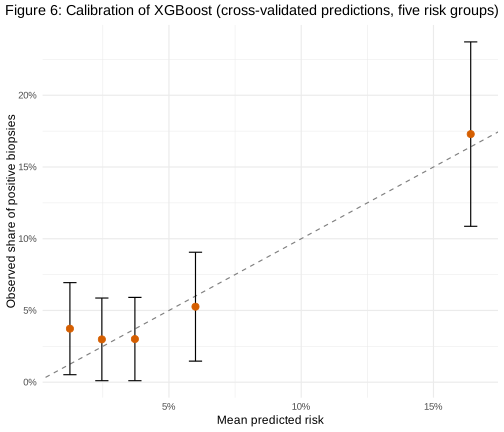

In [29]:
# Step 18: tune the selected model on PR AUC with 5-fold CV on the full training set,
# and check the calibration of its cross-validated predictions (the threshold stays at 5%).
final_spec <- get(paste0("model_", final_model_name))   # e.g. model_xgb
set.seed(123)
final_folds <- suppressWarnings(vfold_cv(train_clean, v = 5, strata = biopsy, pool = 0))
final_splits <- map(final_folds$splits, ~ bake_split(analysis(.x), assessment(.x), final_spec$na_indicators))
grid_rows <- if (nrow(final_spec$grid) > 0) split(final_spec$grid, seq_len(nrow(final_spec$grid))) else list(tibble())

tuning <- map(grid_rows, function(params) {
  probs <- map(final_splits, ~ as.numeric(do.call(final_spec$fit_predict, c(list(.x$train, .x$new), as.list(params)))))
  list(params = params, probs = probs,
       pr_auc = mean(map2_dbl(final_splits, probs, ~ pr_auc(.x$new$biopsy, .y))))
})
best <- tuning[[which.max(map_dbl(tuning, "pr_auc"))]]
best_params <- best$params

# Calibration of the cross-validated predictions of the tuned model
clamp <- function(p) pmin(pmax(p, 1e-6), 1 - 1e-6)
cal_data <- tibble(truth = unlist(map(final_splits, ~ as.character(.x$new$biopsy))), prob = unlist(best$probs)) |>
  mutate(y = as.integer(truth == "yes"), lp = qlogis(clamp(prob)))
cal_int <- glm(y ~ 1, offset = lp, family = binomial, data = cal_data)   # calibration-in-the-large (ideal 0)
cal_slope <- glm(y ~ lp, family = binomial, data = cal_data)              # calibration slope (ideal 1)
ci_int <- confint.default(cal_int)[1, ]
ci_slope <- confint.default(cal_slope)["lp", ]

# Rule fixed in advance: Platt scaling if the 95% CI of the intercept excludes 0 or that of the slope excludes 1.
# Platt scaling is the slope model above, fitted on cross-validated (out-of-fold) predictions only.
use_platt <- ci_int[1] > 0 || ci_int[2] < 0 || ci_slope[1] > 1 || ci_slope[2] < 1
platt <- cal_slope

# Calibration plot: patients grouped into five equal-sized groups of predicted risk
options(repr.plot.width = 7, repr.plot.height = 6)
cal_data |>
  mutate(group = ntile(prob, 5)) |>
  group_by(group) |>
  summarise(predicted = mean(prob), observed = mean(y), n = n(), .groups = "drop") |>
  mutate(se = sqrt(observed * (1 - observed) / n)) |>
  ggplot(aes(predicted, observed)) +
  geom_abline(linetype = "dashed", colour = "grey50") +
  geom_errorbar(aes(ymin = pmax(observed - 1.96 * se, 0), ymax = observed + 1.96 * se), width = 0.005) +
  geom_point(size = 3, colour = "#D55E00") +
  scale_x_continuous(labels = scales::percent) +
  scale_y_continuous(labels = scales::percent) +
  labs(x = "Mean predicted risk", y = "Observed share of positive biopsies",
       title = sprintf("Figure 6: Calibration of %s (cross-validated predictions, five risk groups)",
                       model_names[final_model_name])) +
  theme_minimal(base_size = 12) + centre_title


In [30]:
# Steps 19-22: refit on the full training set, predict the locked test set ONCE, and evaluate
# Step 19: the recipe and the selected model are refitted on all 667 training patients (threshold fixed at 5%)
# Step 20: the test set is unlocked for the first and only time
test_clean <- readRDS("test_locked.rds") |> rename_with(make_clean_names)
stopifnot(nrow(test_clean) == 168)
final_data <- bake_split(train_clean, test_clean, final_spec$na_indicators)
set.seed(4510)
test_prob <- as.numeric(do.call(final_spec$fit_predict, c(list(final_data$train, final_data$new), as.list(best_params))))
if (use_platt) test_prob <- as.numeric(predict(platt, newdata = tibble(lp = qlogis(clamp(test_prob))), type = "response"))
test_truth <- test_clean$biopsy

# Step 21: net benefit at 5% (primary), then the secondary metrics
test_metrics <- function(truth, prob) {
  m <- metrics_at(truth, prob, p_t)
  c(`Net benefit per 1,000: model` = 1000 * net_benefit(truth, prob, p_t),
    `Net benefit per 1,000: biopsy everyone` = 1000 * nb_all(truth, p_t),
    `Net benefit per 1,000: model minus biopsy everyone` = 1000 * (net_benefit(truth, prob, p_t) - nb_all(truth, p_t)),
    Sensitivity = m$sensitivity, Specificity = m$specificity, Precision = m$precision, F1 = m$f1, F2 = m$f2,
    `PR AUC` = pr_auc(truth, prob), `ROC AUC` = roc_auc_vec(truth, prob),
    `Brier score` = mean((prob - (truth == "yes"))^2))
}
estimate <- test_metrics(test_truth, test_prob)

# Step 22: 1,000 bootstrap resamples, drawing positives and negatives separately (stratified),
# so the prevalence, and hence the net benefit of biopsying everyone, is the same in every resample
set.seed(4510)
pos <- which(test_truth == "yes"); neg <- which(test_truth == "no")
boot <- map(1:1000, function(b) {
  i <- c(sample(pos, replace = TRUE), sample(neg, replace = TRUE))
  test_metrics(test_truth[i], test_prob[i])
}) |> do.call(what = rbind)
ci <- apply(boot, 2, quantile, probs = c(0.025, 0.975), na.rm = TRUE)


## Variable Importance

The second aim of the study is explanatory: which risk factors are linked to a positive biopsy? No single method answers this reliably on 667 patients with 43 positives, so three methods with different assumptions are compared. A factor that all three rank highly is more likely to be a real signal than an artefact of one method.

* **LASSO (Table 6, Figure 7)** (Tibshirani, 1996) is fitted on the full training set. The penalty $\lambda$ is chosen by stratified 5-fold cross-validation with the one-standard-error rule (lambda.1se): the largest penalty whose cross-validated deviance is within one standard error of the minimum. This matches the one-SE rule used for model selection and keeps only the most stable predictors; lambda.min is shown for comparison. Because the predictors are standardised, each coefficient is the change in log-odds per standard deviation, and its exponential is an odds ratio. Coefficients that LASSO sets to zero are dropped from the model.
* **Grouped permutation importance (Table 7, Figure 8)** (Breiman, 2001) measures how much the final XGBoost model's PR AUC drops when one block of risk factors is shuffled among the validation patients of the 5-fold cross-validation used for final tuning. Variables that measure the same exposure are strongly correlated (for example Dx:Cancer and Dx:HPV, r = 0.93, and the STD variables, r up to 0.98). If they were shuffled one at a time, the model could use the unshuffled partner instead, and both would look unimportant. Each questionnaire block is therefore shuffled together with its missing-value indicators.
* **Symbolic regression (Table 8)** counts how many of its 50 formulas, one per outer fold, use a variable from each block. Symbolic regression predicted at chance level (ROC AUC 0.52), so these counts are exploratory only.

**Findings.** LASSO at lambda.1se keeps only three blocks: STDs, previous diagnoses and hormonal contraceptives (Table 8). Hormonal contraceptives and previous diagnoses are the top two for permutation importance and symbolic regression. LASSO gives STDs the largest coefficient and previous diagnoses a very close second (both 0.156 to three decimals), and ranks hormonal contraceptives third.

1. **Hormonal contraceptives.** This was the most important block for XGBoost: shuffling it lowered PR AUC by 0.105 on average, and in all 5 folds. It appears in 31 of the 50 symbolic regression formulas. LASSO keeps two of its variables, both with small coefficients. Longer use was linked to slightly higher risk (odds ratio 1.03 per SD of years of use), in line with the known association between long-term hormonal contraceptive use and cervical cancer (Smith et al., 2003). The missing-value indicator has a negative coefficient (odds ratio 0.92): none of the 43 positive patients left the contraceptive questions unanswered, against 84 of the 624 negative patients (13.5%). This is a feature of how the data were recorded, not a biological risk factor, and it may not hold in other hospitals.
2. **Previous diagnoses (Dx:HPV, Dx:CIN, Dx:Cancer).** These were a very close second for LASSO (0.156, as for STDs), second for XGBoost and first for symbolic regression (42 of the 50 formulas). All three diagnoses have positive LASSO coefficients: Dx:HPV (odds ratio 1.17 per SD), Dx:CIN (1.14) and Dx:Cancer (1.14). Of the 15 training patients with a previous HPV diagnosis, 6 had a positive biopsy (40%, against 6.4% overall). This agrees with the literature: persistent high-risk HPV infection is the main cause of cervical cancer, and CIN is its precancerous stage.
3. **STDs.** HIV (odds ratio 1.17 per SD) and genital herpes (1.12) have positive LASSO coefficients, which puts the STD block first for LASSO, just ahead of previous diagnoses. This fits the role of immunosuppression and co-infection in HPV persistence described in the literature review. However, these infections are very rare in the training set: 4 of the 14 patients with HIV had a positive biopsy, and the herpes coefficient rests on a single patient, who was positive. Shuffling the whole STD block changed XGBoost's PR AUC only a little (0.020, and in only 3 of 5 folds). These estimates are therefore unstable and should not be over-interpreted.

**What was not found.** Smoking, IUD use, number of pregnancies, age at first intercourse and number of sexual partners were weak by every method. LASSO dropped all of them, and shuffling them lowered XGBoost's PR AUC by 0.017 or less. Number of sexual partners appears in 11 symbolic regression formulas, but LASSO dropped it and shuffling it slightly improved XGBoost, so it carried no usable signal for the selected model. This does not show that these factors are harmless, since several are established co-factors. It shows only that, in this small and self-reported data set, they add little once hormonal contraceptive use and previous diagnoses are known.

**Link to the test result.** Previous diagnoses were the model's second most important block, and none of the 11 positive patients in the test set had a previous HPV or cancer diagnosis. This helps to explain why its test performance was at chance level.

**Table 6: Non-zero LASSO coefficients (standardised predictors; lambda.1se = 0.0183, lambda.min = 0.0050)**

|Variable                          |Coefficient (lambda.1se) |Odds ratio per SD (lambda.1se) |Coefficient (lambda.min, for comparison) |Odds ratio per SD (lambda.min) |
|:---------------------------------|:------------------------|:------------------------------|:----------------------------------------|:------------------------------|
|STDs:HIV                          |0.156                    |1.17                           |0.219                                    |1.25                           |
|Dx:HPV                            |0.156                    |1.17                           |0.271                                    |1.31                           |
|Dx:CIN                            |0.132                    |1.14                           |0.189                                    |1.21                           |
|Dx:Cancer                         |0.127                    |1.14                           |0.108                                    |1.11                           |
|STDs:genital herpes               |0.114                    |1.12                           |0.172                                    |1.19                           |
|Hormonal Contraceptives (missing) |-0.080                   |0.92                           |-0.521                                   |0.59                           |
|Hormonal Contraceptives (years)   |0.032                    |1.03                           |0.204                                    |1.23                           |
|STDs:syphilis                     |0.000                    |1.00                           |-0.148                                   |0.86                           |
|Num of pregnancies (missing)      |0.000                    |1.00                           |0.122                                    |1.13                           |
|STDs                              |0.000                    |1.00                           |0.120                                    |1.13                           |
|IUD (years)                       |0.000                    |1.00                           |-0.101                                   |0.90                           |
|STDs:HPV                          |0.000                    |1.00                           |-0.083                                   |0.92                           |
|Age                               |0.000                    |1.00                           |-0.063                                   |0.94                           |
|Smokes (missing)                  |0.000                    |1.00                           |-0.057                                   |0.94                           |
|STDs:Hepatitis B                  |0.000                    |1.00                           |-0.036                                   |0.96                           |
|Hormonal Contraceptives           |0.000                    |1.00                           |-0.012                                   |0.99                           |

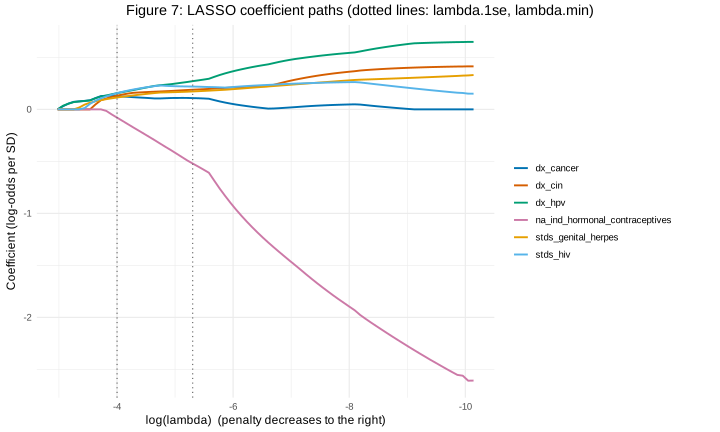

In [31]:
# Step 23: LASSO on the full training set, with lambda chosen by 5-fold CV (cv.glmnet)
suppressPackageStartupMessages(library(glmnet))   # loaded already by the elastic net cell; repeated so this cell runs on its own
# Same recipe as every model (median imputation, missing-value indicators, standardisation), so each
# coefficient is the change in log-odds per 1 SD of the predictor; exp(coefficient) is the odds ratio.
# lambda.1se (the largest lambda within one SE of the lowest CV deviance, i.e. the sparsest model that is about
# as good) is the main result, in line with the one-SE rule used for model selection; lambda.min is shown for comparison.
lasso_data <- bake(prep(make_recipe(train_clean, na_indicators = TRUE)), new_data = NULL)
x_lasso <- as.matrix(select(lasso_data, -biopsy))
y_lasso <- as.integer(lasso_data$biopsy == "yes")

set.seed(4510)
lasso_folds <- suppressWarnings(vfold_cv(lasso_data, v = 5, strata = biopsy, pool = 0))   # stratified, as before
lasso_foldid <- imap_dfr(lasso_folds$splits, ~ tibble(row = complement(.x), fold = .y)) |> arrange(row) |> pull(fold)
cv_lasso <- cv.glmnet(x_lasso, y_lasso, family = "binomial", alpha = 1, foldid = lasso_foldid)

lasso_coefs <- tibble(
  Variable = rownames(coef(cv_lasso, s = "lambda.min"))[-1],
  min = as.numeric(coef(cv_lasso, s = "lambda.min"))[-1],
  se1 = as.numeric(coef(cv_lasso, s = "lambda.1se"))[-1]
) |>
  filter(abs(min) >= 0.0005 | abs(se1) >= 0.0005) |>   # drop coefficients that are zero (to 3 decimals)
  arrange(desc(abs(se1)), desc(abs(min)))              # ranked by lambda.1se (the main result)

original_names <- setNames(names(train), make_clean_names(names(train)))   # e.g. "dx_hpv" -> "Dx:HPV"
pretty_name <- function(v) {
  label <- original_names[sub("^na_ind_", "", v)]
  unname(ifelse(startsWith(v, "na_ind_"), paste(label, "(missing)"), label))
}

lasso_coefs |>
  transmute(Variable = pretty_name(Variable),
            `Coefficient (lambda.1se)` = sprintf("%.3f", se1),
            `Odds ratio per SD (lambda.1se)` = sprintf("%.2f", exp(se1)),
            `Coefficient (lambda.min, for comparison)` = sprintf("%.3f", min),
            `Odds ratio per SD (lambda.min)` = sprintf("%.2f", exp(min))) |>
  show_table(sprintf("Table 6: Non-zero LASSO coefficients (standardised predictors; lambda.1se = %.4f, lambda.min = %.4f)",
                     cv_lasso$lambda.1se, cv_lasso$lambda.min))

# Coefficient path: how each coefficient grows as the penalty is relaxed
options(repr.plot.width = 10, repr.plot.height = 6)
path <- as.matrix(cv_lasso$glmnet.fit$beta)
as_tibble(t(path)) |>
  mutate(log_lambda = log(cv_lasso$glmnet.fit$lambda)) |>
  pivot_longer(-log_lambda, names_to = "Variable", values_to = "coef") |>
  filter(Variable %in% head(lasso_coefs$Variable, 6)) |>   # the six largest at lambda.1se
  ggplot(aes(log_lambda, coef, colour = Variable)) +
  geom_line(linewidth = 0.9) +
  geom_vline(xintercept = log(c(cv_lasso$lambda.min, cv_lasso$lambda.1se)), linetype = "dotted", colour = "grey40") +
  scale_x_reverse() +
  scale_colour_manual(values = c("#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9")) +
  labs(x = "log(lambda)  (penalty decreases to the right)", y = "Coefficient (log-odds per SD)", colour = NULL,
       title = "Figure 7: LASSO coefficient paths (dotted lines: lambda.1se, lambda.min)") +
  theme_minimal(base_size = 12) + centre_title


**Table 7: Grouped permutation importance for XGBoost (10 shuffles per block and fold)**

|Risk-factor block        | Columns permuted|Drop in PR AUC (mean ± SD over 5 folds) | Folds with a drop (of 5)|
|:------------------------|----------------:|:---------------------------------------|------------------------:|
|Hormonal contraceptives  |                4|0.105 ± 0.072                           |                        5|
|Previous diagnoses (Dx)  |                4|0.068 ± 0.049                           |                        5|
|Age                      |                1|0.022 ± 0.063                           |                        4|
|STDs                     |               23|0.020 ± 0.022                           |                        3|
|Pregnancies              |                2|0.017 ± 0.044                           |                        3|
|First sexual intercourse |                2|0.013 ± 0.048                           |                        3|
|Smoking                  |                6|0.013 ± 0.034                           |                        2|
|IUD                      |                4|-0.003 ± 0.011                          |                        3|
|Sexual partners          |                2|-0.032 ± 0.023                          |                        0|

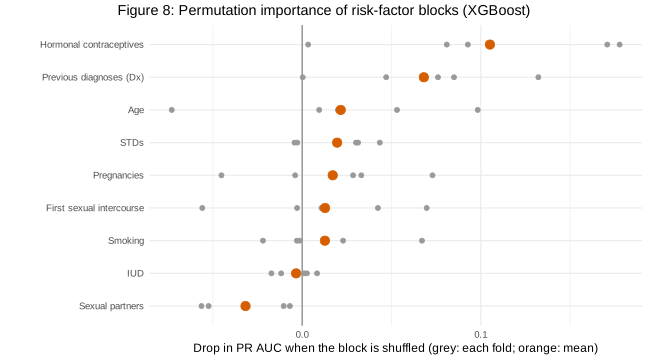

In [32]:
# Step 24: grouped permutation importance (drop in PR AUC) for the selected model, on the CV folds of Step 18
# Correlated variables measure the same exposure (e.g. Dx:Cancer and Dx:HPV, r = 0.93), so they are permuted
# together, block by block, and each variable is permuted together with its missing-value indicator.
# Each fold's model is refitted with the same seed for every permutation, so it is the same model each time
# (checked below); only the validation patients' values of one block are shuffled.
risk_blocks <- list(
  Age = "age", `Sexual partners` = "number_of_sexual_partners",
  `First sexual intercourse` = "first_sexual_intercourse", Pregnancies = "num_of_pregnancies",
  Smoking = "^smokes", `Hormonal contraceptives` = "^hormonal_contraceptives", IUD = "^iud",
  STDs = "^stds", `Previous diagnoses (Dx)` = "^dx"
)
block_cols <- function(cols, pattern) {
  base <- sub("^na_ind_", "", cols)
  cols[if (startsWith(pattern, "^")) grepl(pattern, base) else base == pattern]
}

n_perm <- 10
perm_importance <- imap_dfr(final_splits, function(b, k) {
  fit_with_seed <- function(new) {
    set.seed(4510 + k)
    as.numeric(do.call(final_spec$fit_predict, c(list(b$train, new), as.list(best_params))))
  }
  base_prob <- fit_with_seed(b$new)
  stopifnot(isTRUE(all.equal(base_prob, fit_with_seed(b$new))))   # the refit gives the same model
  base_pr <- pr_auc(b$new$biopsy, base_prob)
  imap_dfr(risk_blocks, function(pattern, block) {
    cols <- block_cols(names(b$new), pattern)
    drops <- map_dbl(seq_len(n_perm), function(r) {
      set.seed(1000 * k + r)
      shuffled <- b$new
      shuffled[cols] <- b$new[sample(nrow(b$new)), cols]   # one shuffle for the whole block keeps it consistent
      base_pr - pr_auc(b$new$biopsy, fit_with_seed(shuffled))
    })
    tibble(fold = k, block = block, n_cols = length(cols), drop = mean(drops))
  })
})

perm_summary <- perm_importance |>
  group_by(block) |>
  summarise(n_cols = first(n_cols), mean_drop = mean(drop), sd_drop = sd(drop),
            folds_positive = sum(drop > 0), .groups = "drop") |>
  arrange(desc(mean_drop))

perm_summary |>
  transmute(`Risk-factor block` = block, `Columns permuted` = n_cols,
            `Drop in PR AUC (mean ± SD over 5 folds)` = sprintf("%.3f ± %.3f", mean_drop, sd_drop),
            `Folds with a drop (of 5)` = folds_positive) |>
  show_table(sprintf("Table 7: Grouped permutation importance for %s (%d shuffles per block and fold)",
                     model_names[final_model_name], n_perm))

options(repr.plot.width = 9, repr.plot.height = 5)
perm_importance |>
  mutate(block = factor(block, levels = rev(perm_summary$block))) |>
  ggplot(aes(drop, block)) +
  geom_vline(xintercept = 0, colour = "grey50") +
  geom_point(colour = "grey60", size = 2) +
  stat_summary(fun = mean, geom = "point", colour = "#D55E00", size = 4) +
  labs(x = "Drop in PR AUC when the block is shuffled (grey: each fold; orange: mean)", y = NULL,
       title = sprintf("Figure 8: Permutation importance of risk-factor blocks (%s)", model_names[final_model_name])) +
  theme_minimal(base_size = 12) + centre_title


In [33]:
# Step 25: compare the three views of importance, block by block
# - LASSO: the largest absolute coefficient in the block at lambda.1se (0 = block dropped)
# - permutation importance: the drop in PR AUC from Table 7
# - symbolic regression: how many of its 50 formulas (one per outer fold) use any variable from the block
sr_formula_vars <- cv_all$sr$formulas |> select(fold, vars) |> unnest(vars)

map_dfr(names(risk_blocks), function(block) {
  pattern <- risk_blocks[[block]]
  tibble(block = block,
         lasso = max(c(0, abs(filter(lasso_coefs, Variable %in% block_cols(Variable, pattern))$se1))),
         sr = n_distinct(filter(sr_formula_vars, vars %in% block_cols(vars, pattern))$fold))
}) |>
  left_join(select(perm_summary, block, mean_drop), by = "block") |>
  mutate(rank_lasso = min_rank(desc(lasso)), rank_perm = min_rank(desc(mean_drop)), rank_sr = min_rank(desc(sr))) |>
  arrange(rank_perm) |>
  transmute(`Risk-factor block` = block,
            `LASSO: largest absolute coefficient` = sprintf("%.3f (rank %d)", lasso, rank_lasso),
            `Permutation: drop in PR AUC` = sprintf("%.3f (rank %d)", mean_drop, rank_perm),
            `Symbolic regression: formulas using it (of 50)` = sprintf("%d (rank %d)", sr, rank_sr)) |>
  show_table("Table 8: Importance of each risk-factor block by three methods")


**Table 8: Importance of each risk-factor block by three methods**

|Risk-factor block        |LASSO: largest absolute coefficient |Permutation: drop in PR AUC |Symbolic regression: formulas using it (of 50) |
|:------------------------|:-----------------------------------|:---------------------------|:----------------------------------------------|
|Hormonal contraceptives  |0.080 (rank 3)                      |0.105 (rank 1)              |31 (rank 2)                                    |
|Previous diagnoses (Dx)  |0.156 (rank 2)                      |0.068 (rank 2)              |42 (rank 1)                                    |
|Age                      |0.000 (rank 4)                      |0.022 (rank 3)              |3 (rank 6)                                     |
|STDs                     |0.156 (rank 1)                      |0.020 (rank 4)              |16 (rank 3)                                    |
|Pregnancies              |0.000 (rank 4)                      |0.017 (rank 5)              |2 (rank 8)                                     |
|First sexual intercourse |0.000 (rank 4)                      |0.013 (rank 6)              |3 (rank 6)                                     |
|Smoking                  |0.000 (rank 4)                      |0.013 (rank 7)              |5 (rank 5)                                     |
|IUD                      |0.000 (rank 4)                      |-0.003 (rank 8)             |2 (rank 8)                                     |
|Sexual partners          |0.000 (rank 4)                      |-0.032 (rank 9)             |11 (rank 4)                                    |


# Conclusion
This study compared five machine learning models to predict cervical biopsy outcomes using demographic, behavioural, and medical risk factors. While TabPFN achieved the highest cross-validation net benefit (24.9 per 1,000 patients), XGBoost (23.4 per 1,000) was selected as the final model due to its comparable performance and lower complexity under the one-standard-error rule, although no difference between the models, or between a model and biopsying everyone, was statistically significant. However, XGBoost's performance declined on the independent test set, achieving an ROC AUC of 0.453 and a lower net benefit (6.0 per 1,000) than the biopsy-everyone strategy (16.3 per 1,000) at the prespecified 5% decision threshold. One likely reason is that none of the 11 test positives had a prior HPV or cancer diagnosis. These findings indicate limited generalisability and clinical utility on this small cohort.

Variable importance was assessed using three complementary approaches: LASSO regression, grouped permutation importance, and symbolic regression, which evaluated predictor relevance through coefficient shrinkage, changes in predictive performance, and formula selection frequency, respectively. Across the three approaches, previous diagnoses (`Dx:HPV`, `Dx:CIN`, `Dx:Cancer`) and hormonal contraceptive use were the most consistent risk factors for a positive cervical biopsy. Sexually transmitted diseases ranked highly only for LASSO, where the estimate rests on very few patients.

Overall, these findings highlight the challenges of developing generalisable predictive models using small, highly imbalanced clinical datasets. Larger and more representative datasets—particularly with a greater number of positive biopsy cases—and external validation across multiple clinics are needed before clinical implementation.

## Future Directions
Future research should explore alternative approaches to handling informative missingness and severe class imbalance, such as multiple imputation and hierarchical shrinkage, as well as integrating low-cost molecular HPV triage tests alongside self-reported questionnaires. Given the limited number of positive biopsy cases in this dataset, further sensitivity analyses across multi-centre cohorts should also be conducted to assess how preprocessing assumptions affect calibration and the stability of variable importance rankings.



# References

* Breiman, L. (2001). Random forests. *Machine Learning*, *45*(1), 5–32. <https://doi.org/10.1023/A:1010933404324>
* Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). Association for Computing Machinery. <https://doi.org/10.1145/2939672.2939785>
* Fernandes, K., Cardoso, J. S., & Fernandes, J. (2017). Transfer learning with partial observability applied to cervical cancer screening. In L. A. Alexandre, J. Salvador Sánchez, & J. M. F. Rodrigues (Eds.), *Pattern recognition and image analysis* (pp. 243–250). Springer International Publishing. <https://doi.org/10.1007/978-3-319-58838-4_27>
* Hollmann, N., Müller, S., Purucker, L., Krishnakumar, A., Körfer, M., Hoo, S. B., Schirrmeister, R. T., & Hutter, F. (2025). Accurate predictions on small data with a tabular foundation model. *Nature*, *637*(8045), 319–326. <https://doi.org/10.1038/s41586-024-08328-6>
* Karatzoglou, A., Smola, A., Hornik, K., & Zeileis, A. (2004). kernlab – An S4 package for kernel methods in R. *Journal of Statistical Software*, *11*(9), 1–20. <https://doi.org/10.18637/jss.v011.i09>
* Koza, J. R. (1992). *Genetic programming: On the programming of computers by means of natural selection*. MIT Press.
* Müller, S., Hollmann, N., Pineda Arango, S., Grabocka, J., & Hutter, F. (2022). Transformers can do Bayesian inference. In *International Conference on Learning Representations*. <https://openreview.net/forum?id=KSugKcbNf9>
* Nadeau, C., & Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, *52*(3), 239–281. <https://doi.org/10.1023/A:1024068626366>
* Noorian, F., de Silva, A. M., & Leong, P. H. W. (2016). gramEvol: Grammatical evolution in R. *Journal of Statistical Software*, *71*(1), 1–26. <https://doi.org/10.18637/jss.v071.i01>
* O'Neill, M., & Ryan, C. (2001). Grammatical evolution. *IEEE Transactions on Evolutionary Computation*, *5*(4), 349–358. <https://doi.org/10.1109/4235.942529>
* Perkins, R. B., Guido, R. S., Castle, P. E., Chelmow, D., Einstein, M. H., Garcia, F., Huh, W. K., Kim, J. J., Moscicki, A.-B., Nayar, R., Saraiya, M., Sawaya, G. F., Wentzensen, N., & Schiffman, M. (2020). 2019 ASCCP risk-based management consensus guidelines for abnormal cervical cancer screening tests and cancer precursors. *Journal of Lower Genital Tract Disease*, *24*(2), 102–131. <https://doi.org/10.1097/LGT.0000000000000525>
* Rasmussen, C. E., & Williams, C. K. I. (2006). *Gaussian processes for machine learning*. MIT Press. <https://doi.org/10.7551/mitpress/3206.001.0001>
* Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, *10*(3), Article e0118432. <https://doi.org/10.1371/journal.pone.0118432>
* Smith, J. S., Green, J., Berrington de González, A., Appleby, P., Peto, J., Plummer, M., Franceschi, S., & Beral, V. (2003). Cervical cancer and use of hormonal contraceptives: A systematic review. *The Lancet*, *361*(9364), 1159–1167. <https://doi.org/10.1016/S0140-6736(03)12949-2>
* Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society: Series B (Methodological)*, *58*(1), 267–288. <https://doi.org/10.1111/j.2517-6161.1996.tb02080.x>
* Vickers, A. J., & Elkin, E. B. (2006). Decision curve analysis: A novel method for evaluating prediction models. *Medical Decision Making*, *26*(6), 565–574. <https://doi.org/10.1177/0272989X06295361>
* World Health Organization. (2026, November 10). *Cervical cancer* [Fact sheet]. Retrieved November 19, 2026, from <https://www.who.int/news-room/fact-sheets/detail/cervical-cancer>
* Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B (Statistical Methodology)*, *67*(2), 301–320. <https://doi.org/10.1111/j.1467-9868.2005.00503.x>


# Declaration of Generative AI Use
The research question, dataset selection, preprocessing pipeline, model implementations, evaluation framework, and statistical interpretations were developed and carried out by the team. Generative AI tools were used only to refine the wording and conciseness of the written sections, format LaTeX equations and Beamer presentation slides, and assist with exporting the Colab notebook to a clean PDF report.


